# **Part 1: Data Loading &amp; Initial Exploration**

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
df = pd.read_csv('/content/drive/MyDrive/train.csv')

In [5]:
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [6]:
df.shape


(891, 12)

**Basic Descriptive Statistics**

In [7]:
numerical_stats = df.describe()
print(numerical_stats)

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [8]:
mode_values = df.mode().iloc[0]
print("Mode values for numerical features:\n", mode_values)

Mode values for numerical features:
 PassengerId                      1
Survived                       0.0
Pclass                         3.0
Name           Abbing, Mr. Anthony
Sex                           male
Age                           24.0
SibSp                          0.0
Parch                          0.0
Ticket                        1601
Fare                          8.05
Cabin                      B96 B98
Embarked                         S
Name: 0, dtype: object


**Summarize Categorical Variables** like:Sex, Embarked, and Pclass.
Summarize them using the .value_counts() function.

In [9]:
categorical_columns = ['Sex', 'Pclass', 'Embarked']
for column in categorical_columns:
    print(f"Value counts for {column}:")
    print(df[column].value_counts())
    print("\n")

Value counts for Sex:
Sex
male      577
female    314
Name: count, dtype: int64


Value counts for Pclass:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64


Value counts for Embarked:
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64




**Visualization: Histograms and Box Plots**
Histograms are used visualize the distributions of numerical features like Age, Fare, etc. and box plots to identify outliers.

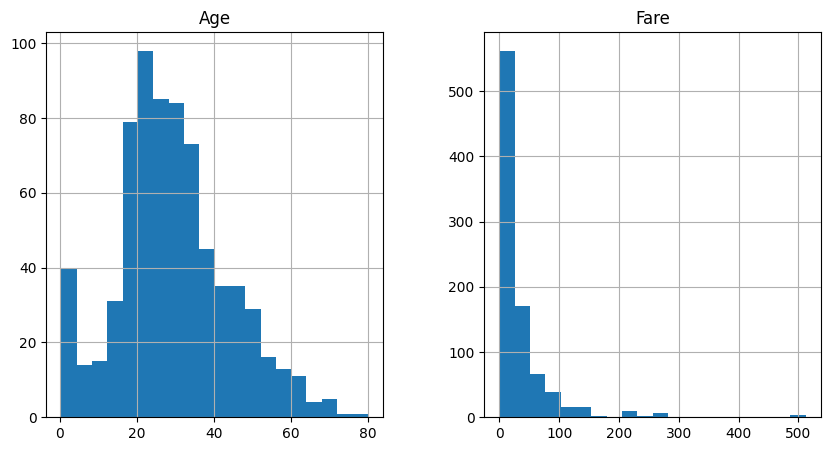

In [10]:
df.hist(column=['Age', 'Fare'], figsize=(10, 5), bins=20) #HISTOGRAM
plt.show()

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


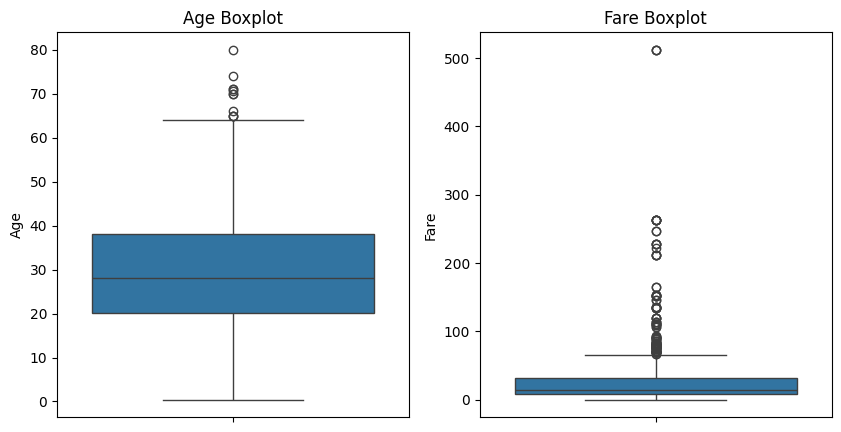

In [11]:
plt.figure(figsize=(10, 5))# Box Plot for Age and Fare
plt.subplot(1, 2, 1)
sns.boxplot(data=df, y='Age')# Age Boxplot
plt.title('Age Boxplot')
plt.subplot(1, 2, 2)
sns.boxplot(data=df, y='Fare')# Fare Boxplot
plt.title('Fare Boxplot')
plt.show()

# **Part 2: Handling Missing Values**

**Identifying Missing Values**

Firstly uuse .isnull() and .info() to identify missing data.

In [12]:
missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values)
df.info() # Summary

Missing values per column:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5

**Visualization**

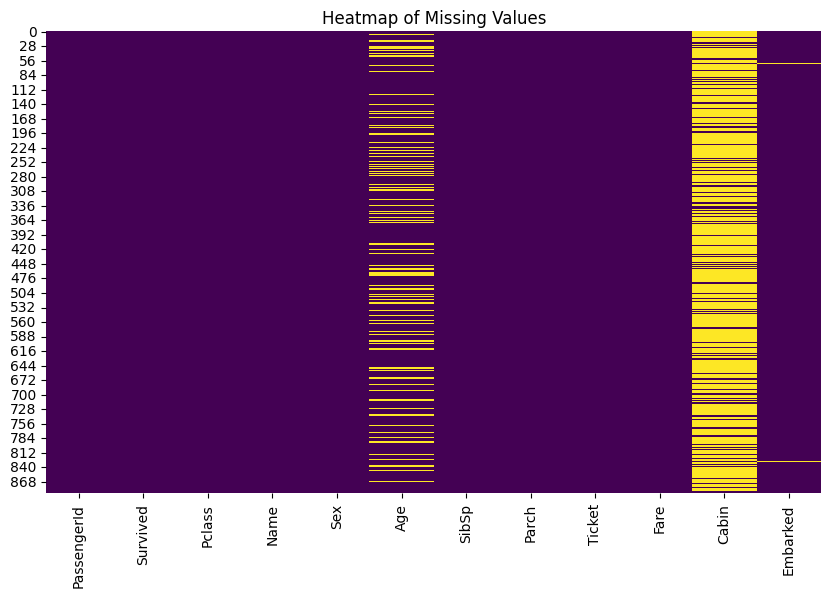

In [13]:
plt.figure(figsize=(10, 6)) #HEATMAP
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Heatmap of Missing Values")
plt.show()

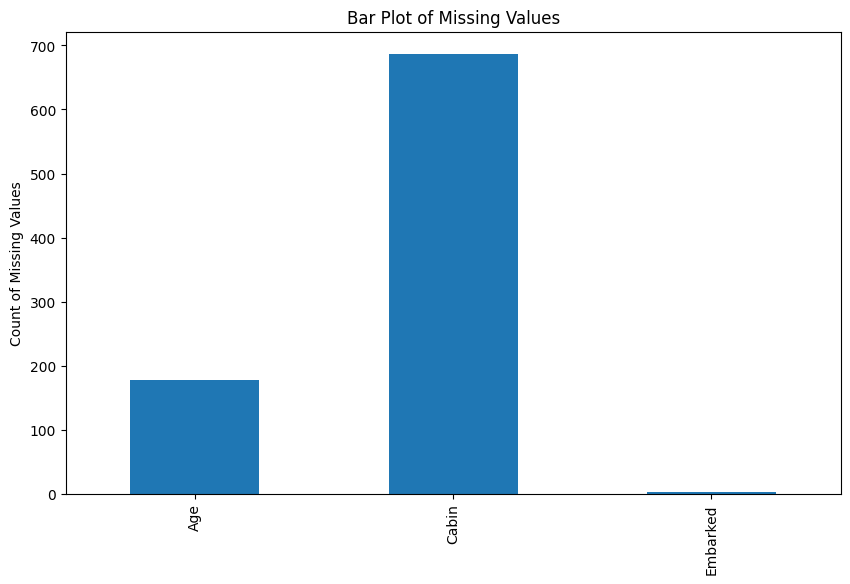

In [14]:
missing_counts = df.isnull().sum()# Bar plot showing the count of missing values
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(10, 6))
missing_counts.plot(kind='bar')
plt.title("Bar Plot of Missing Values")
plt.ylabel("Count of Missing Values")
plt.show()

**Handling Missing AGE Data**

Age is a numerical feature, we can use mean or median imputation. For Age, the median is more robust to outliers.

In [15]:
median_age = df['Age'].median()
df['Age'].fillna(median_age, inplace=True) # Imputing missing Age values with the median
print(f"Missing values in Age after imputation: {df['Age'].isnull().sum()}")

Missing values in Age after imputation: 0


<ipython-input-15-49e8d3a66a3d>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(median_age, inplace=True) # Imputing missing Age values with the median


**Handling Missing Cabin Values**
The Cabin column has a large number of missing values. One option is to drop the column because it has too many missing entries (over 70%). Alternatively, we can impute a placeholder value like 'Unknown'.

In [16]:
# Drop Cabin column (since it has too many missing values)
df.drop(columns=['Cabin'], inplace=True)
print(f"Missing values in Cabin after dropping column: {df.isnull().sum()}")

Missing values in Cabin after dropping column: PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64


In [17]:
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')


 **Handling Missing Embarked Values**

There areonly 2 missing values for Embarked categorical feature, we can use mode to fill missing values.

In [18]:
mode_embarked = df['Embarked'].mode()[0]
df['Embarked'].fillna(mode_embarked, inplace=True)

print(f"Missing values in Embarked after imputation: {df['Embarked'].isnull().sum()}")

Missing values in Embarked after imputation: 0


<ipython-input-18-cf8635bbc093>:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Embarked'].fillna(mode_embarked, inplace=True)


In [19]:
print("Remaining missing values:\n", df.isnull().sum())

Remaining missing values:
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


**Visualization after handling Missing Values**

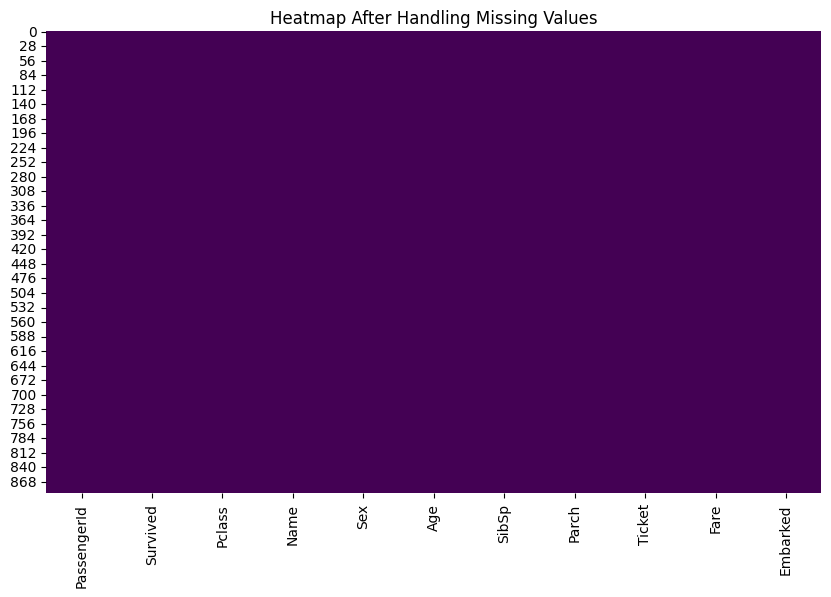

In [20]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Heatmap After Handling Missing Values")
plt.show()


# **Part 3: Detecting &amp; Handling Outliers**

Visualizing Outliers Using Histograms and Box Plots

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


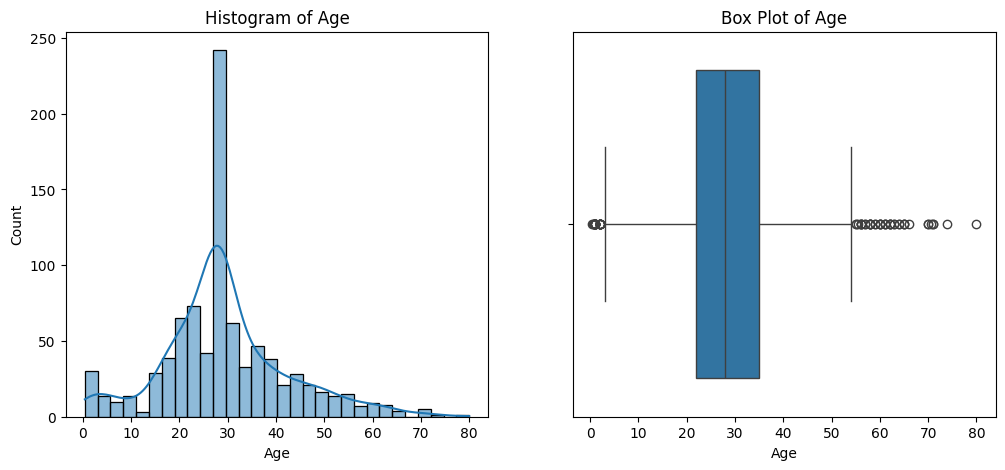

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


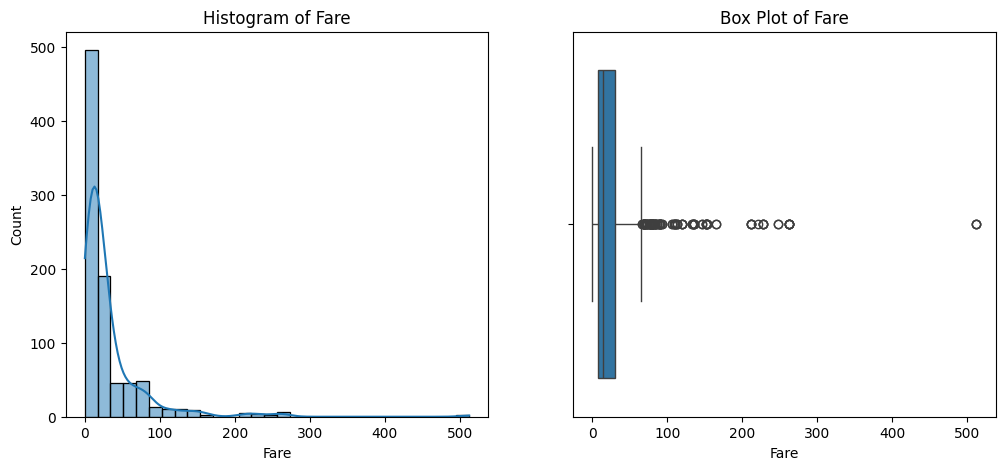

In [21]:
numerical_cols = ['Age', 'Fare']
for col in numerical_cols:
    plt.figure(figsize=(12, 5))
    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f'Histogram of {col}')
    # Box plot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col].dropna())
    plt.title(f'Box Plot of {col}')
    plt.show()

**Statistical Detection of Outliers**

Z-score tells how many standard deviations a value is from the mean. A common threshold is a Z-score greater than 3 or less than -3 (indicating an outlier).

In [22]:
from scipy import stats
df['Age_zscore'] = stats.zscore(df['Age'].dropna())# Z-score calculation
df['Fare_zscore'] = stats.zscore(df['Fare'].dropna())
age_outliers_z = df[(df['Age_zscore'] > 3) | (df['Age_zscore'] < -3)] # Filteringout points with -3>Z-score>3
fare_outliers_z = df[(df['Fare_zscore'] > 3) | (df['Fare_zscore'] < -3)]

print(f"Number of Age outliers based on Z-score: {len(age_outliers_z)}")
print(f"Number of Fare outliers based on Z-score: {len(fare_outliers_z)}")


Number of Age outliers based on Z-score: 7
Number of Fare outliers based on Z-score: 20


**IQR Method**

The IQR method is based on the first (Q1) and third quartiles (Q3), and any value beyond 1.5 times the IQR (Interquartile Range) is considered an outlier.

In [23]:
Q1 = df['Fare'].quantile(0.25)# Calculate Q1 (25th percentile)
Q3 = df['Fare'].quantile(0.75) #Q3 (75th percentile)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR# Defining range for outliers
upper_bound = Q3 + 1.5 * IQR
fare_outliers_iqr = df[(df['Fare'] < lower_bound) | (df['Fare'] > upper_bound)]
print(f"Number of Fare outliers based on IQR: {len(fare_outliers_iqr)}")# Identify Fare outliers
Q1_age = df['Age'].quantile(0.25)# Similarly, apply IQR to other numerical features like Age
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age
lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age
age_outliers_iqr = df[(df['Age'] < lower_bound_age) | (df['Age'] > upper_bound_age)]
print(f"Number of Age outliers based on IQR: {len(age_outliers_iqr)}")


Number of Fare outliers based on IQR: 116
Number of Age outliers based on IQR: 66


In [24]:
# 1. Calculate the outlier thresholds using IQR
Q1_age = df['Age'].quantile(0.25)
Q3_age = df['Age'].quantile(0.75)
IQR_age = Q3_age - Q1_age
lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age

Q1_fare = df['Fare'].quantile(0.25)
Q3_fare = df['Fare'].quantile(0.75)
IQR_fare = Q3_fare - Q1_fare
lower_bound_fare = Q1_fare - 1.5 * IQR_fare
upper_bound_fare = Q3_fare + 1.5 * IQR_fare

# 2. Identify the outliers
age_outliers = df[(df['Age'] < lower_bound_age) | (df['Age'] > upper_bound_age)]
fare_outliers = df[(df['Fare'] < lower_bound_fare) | (df['Fare'] > upper_bound_fare)]

# 3. Display the outliers
print("Age outliers:")
print(age_outliers[['Age']])

print("Fare outliers:")
print(fare_outliers[['Fare']])

# 4. Check the ranges
print(f"Age lower bound: {lower_bound_age}, upper bound: {upper_bound_age}")
print(f"Fare lower bound: {lower_bound_fare}, upper bound: {upper_bound_fare}")


Age outliers:
       Age
7     2.00
11   58.00
15   55.00
16    2.00
33   66.00
..     ...
827   1.00
829  62.00
831   0.83
851  74.00
879  56.00

[66 rows x 1 columns]
Fare outliers:
         Fare
1     71.2833
27   263.0000
31   146.5208
34    82.1708
52    76.7292
..        ...
846   69.5500
849   89.1042
856  164.8667
863   69.5500
879   83.1583

[116 rows x 1 columns]
Age lower bound: 2.5, upper bound: 54.5
Fare lower bound: -26.724, upper bound: 65.6344


**AGE OUTLIERSS:** Presence of ages like 2 and 0.83 suggests that some passengers were very young or might not have had accurate age data recorded.
The upper outliers like 58 and 66 are plausible ages for adult passengers.
**Decision:** It may be appropriate to remove extreme values like 0.83 and consider capping the higher outliers (e.g., ages above 54.5) to 54.5 if they seem to be valid entries. However, based on context, you might keep valid extreme ages like 58 and 66 as they could represent real passengers.

In [25]:
df['Age'] = df['Age'].apply(lambda x: 54.5 if x > 54.5 else x)

**FARE OUTLIERSS** The upper outliers like 263 are significant and should be examined more closely; they may represent first-class fares or premium ticket purchases.
The lower bound being negative indicates a flaw in the IQR calculation, as fare cannot be negative.
**Decision:** Remove outliers below the calculated lower bound (which doesn't make sense in this context) and cap the fares at 65.6344 since this boundary seems to represent the 99th percentile or upper limit of reasonable fare for most passengers.

In [26]:
df['Fare'] = df['Fare'].apply(lambda x: 65.6344 if x > 65.6344 else x)

**Visualization after removing OUTLIERS**

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


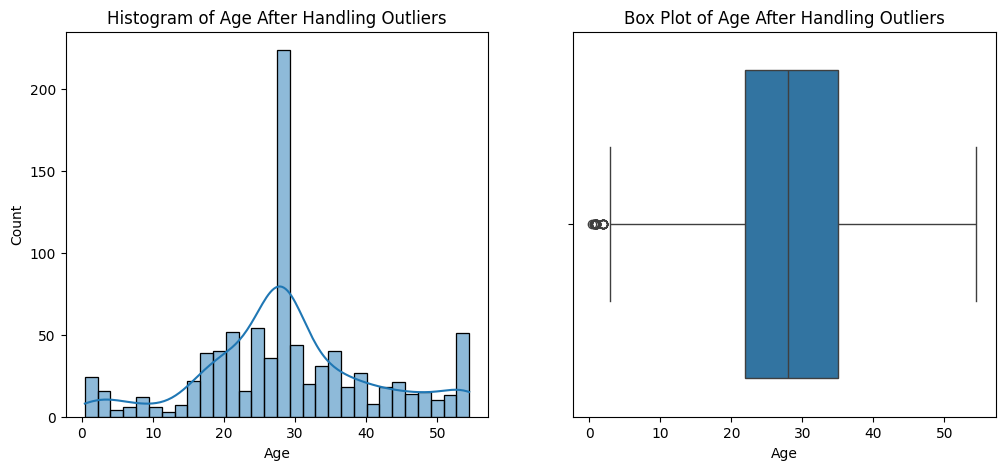

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


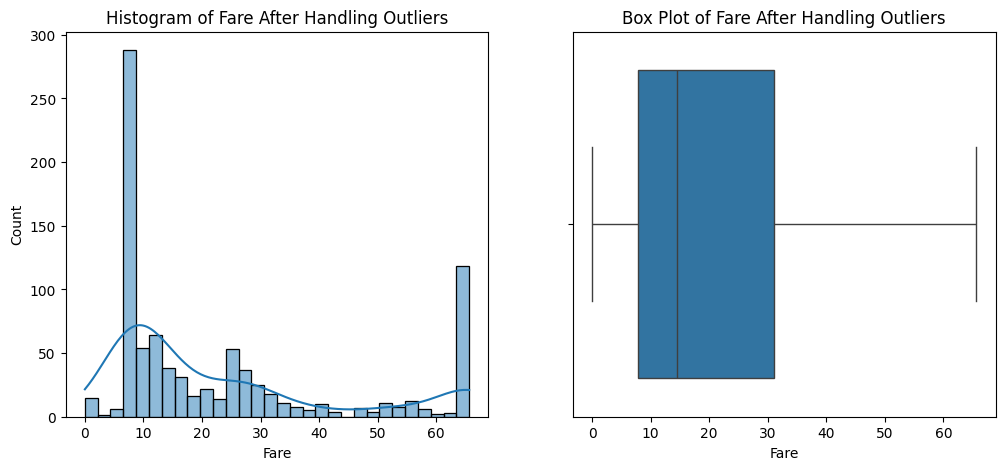

In [27]:
# Create histograms and box plots after handling outliers
for col in numerical_cols:
    plt.figure(figsize=(12, 5))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f'Histogram of {col} After Handling Outliers')

    # Box plot
    plt.subplot(1, 2, 2)
    sns.boxplot(x=df[col].dropna())
    plt.title(f'Box Plot of {col} After Handling Outliers')

    plt.show()

# **Part 4: Dealing with Duplicates**

In [28]:
duplicates = df.duplicated()
num_duplicates = duplicates.sum()# Step 2: Count duplicates
print(f"Number of duplicate records found: {num_duplicates}")
if num_duplicates > 0: #Removing  duplicates if they exist
    df.drop_duplicates(inplace=True)
    print(f"Duplicates removed. New dataset size: {len(df)} records.")
else:
    print("No duplicates found. Dataset size remains the same.")

Number of duplicate records found: 0
No duplicates found. Dataset size remains the same.


# **Part 5: Encoding Categorical Variables**

In [29]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Age_zscore,Fare_zscore
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,-0.565736,-0.502445
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,65.6344,C,0.663861,0.786845
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,-0.258337,-0.488854
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,0.433312,0.420730
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0.433312,-0.486337


In [30]:
df.shape

(891, 13)

In [31]:
#Apply Label Encoding for the ordinal variable 'Pclass'
df['Pclass_encoded'] = df['Pclass'].astype('category').cat.codes

# Step 3: Apply One-Hot Encoding for nominal variables 'Sex' and 'Embarked'
df = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)

# Display the DataFrame after encoding
print(df)

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name   Age  SibSp  Parch  \
0                              Braund, Mr. Owen Harris  22.0      1      0   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0      1      0   
2                               Heikkinen, Miss. Laina  26.0      0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0      1      0   
4                             Allen, Mr. William Henry  35.0      0      0   
..                                                 ...   ...    ...    ... 

<ipython-input-32-18d12ce9d17c>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pclass', data=df, palette='Set2')
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like,

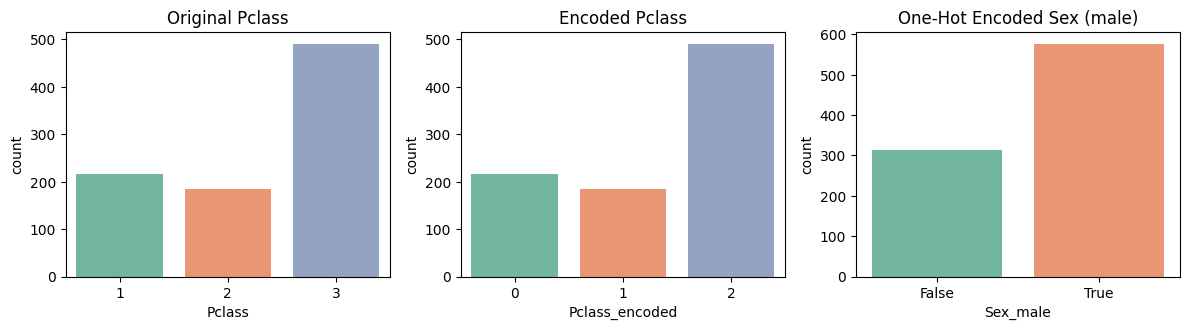

In [32]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 3, 1) # Count plots for original and encoded variables
sns.countplot(x='Pclass', data=df, palette='Set2')
plt.title('Original Pclass')
plt.subplot(2, 3, 2)
sns.countplot(x='Pclass_encoded', data=df, palette='Set2')
plt.title('Encoded Pclass')
plt.subplot(2, 3, 3)
sns.countplot(x='Sex_male', data=df, palette='Set2')
plt.title('One-Hot Encoded Sex (male)')
plt.tight_layout()
plt.show()

# **Part 6: Data Distribution &amp; Visualization**

**For Numerical Features:**

/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/usr/local/lib/python3.10/dist-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


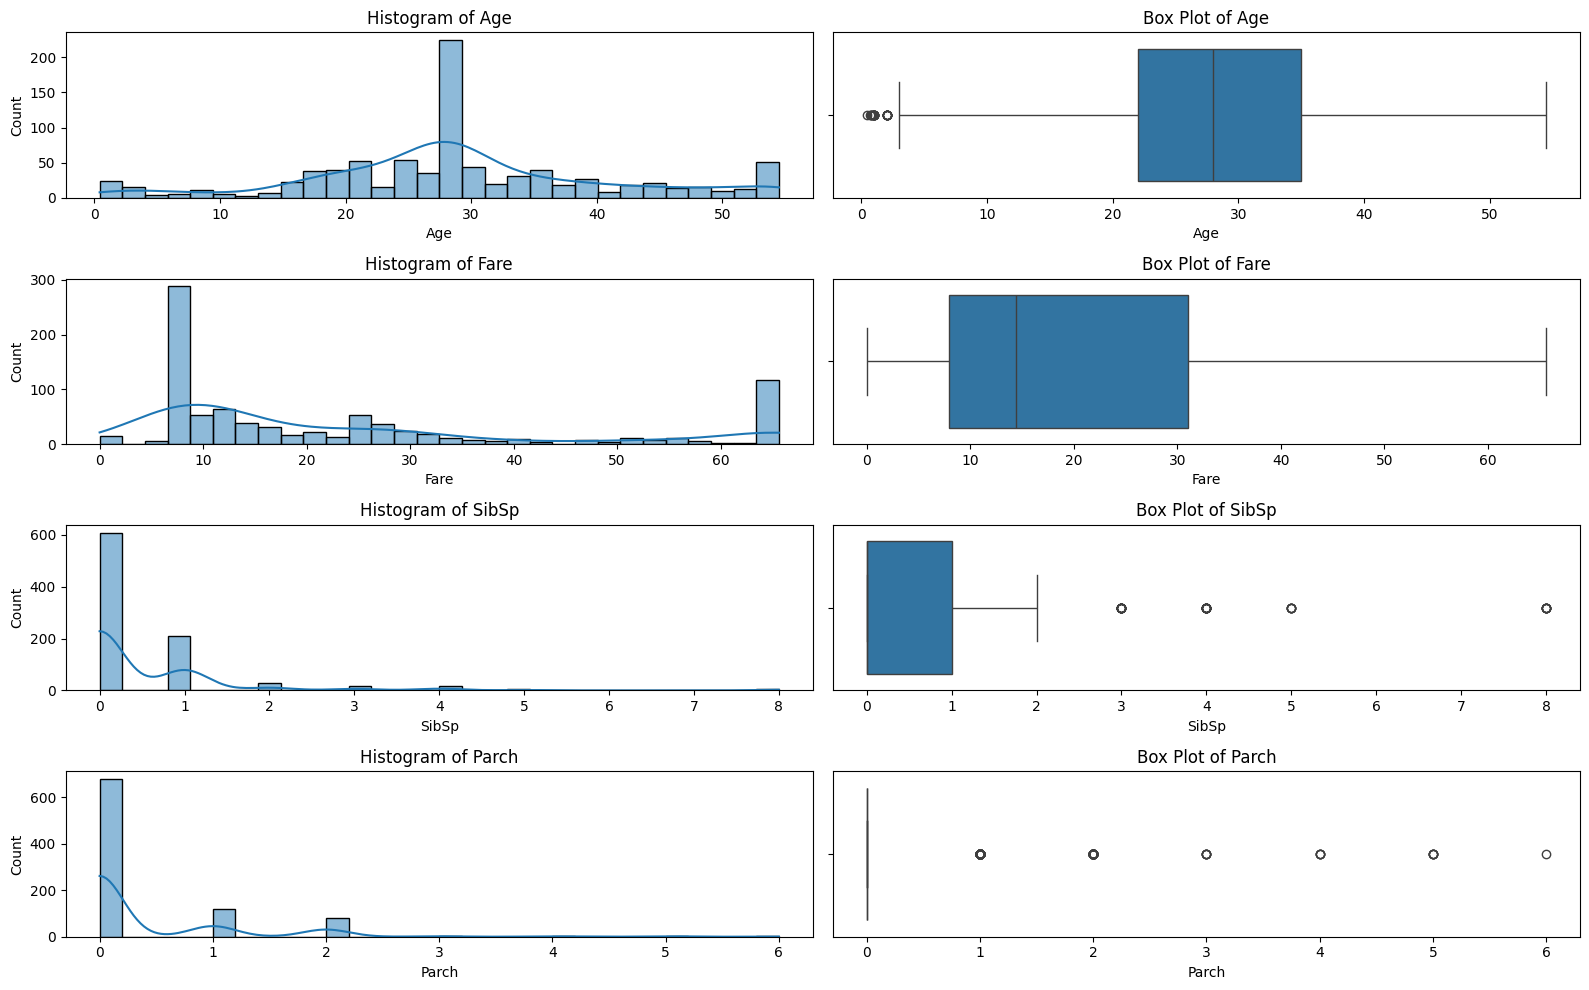

In [33]:
numerical_cols = ['Age', 'Fare', 'SibSp', 'Parch']
plt.figure(figsize=(16, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 2, i * 2 + 1)
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f'Histogram of {col}')

    plt.subplot(4, 2, i * 2 + 2)
    sns.boxplot(x=df[col].dropna())
    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()


Pair plot to visualize relationships between numerical features

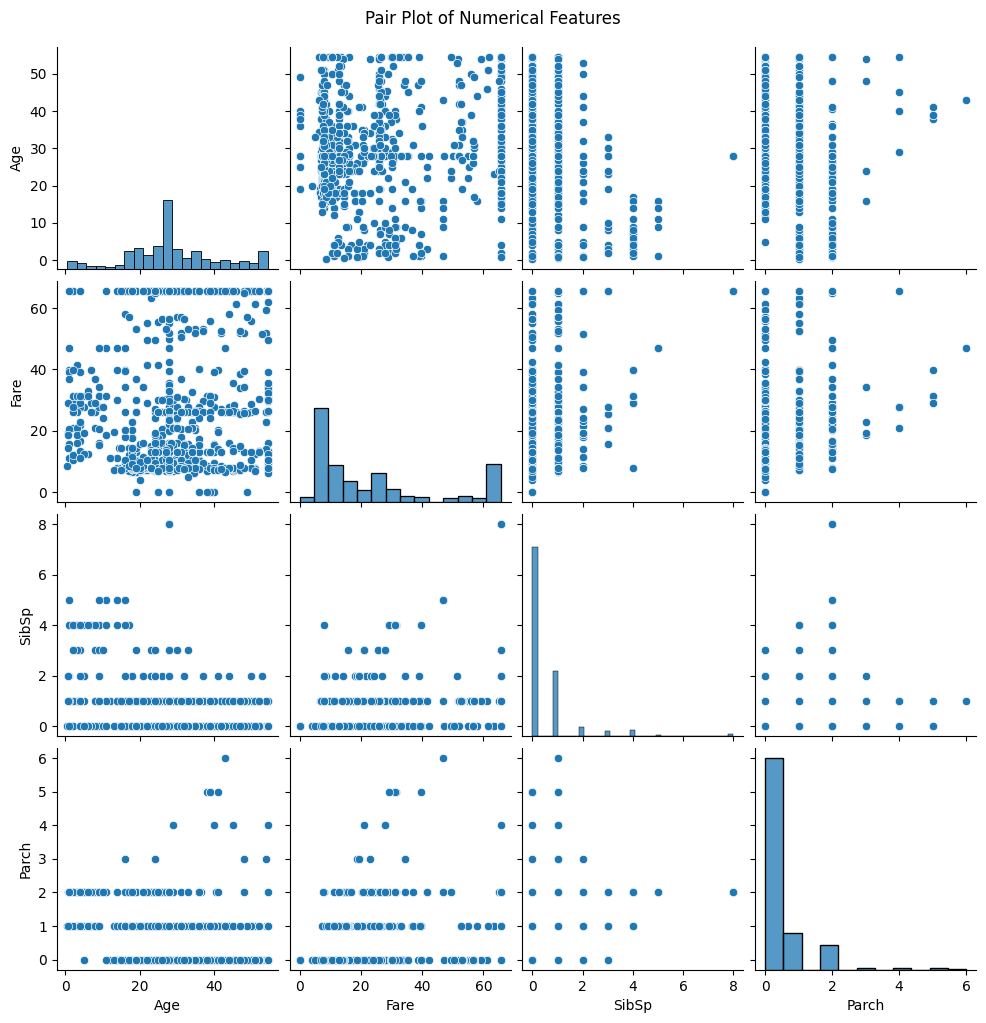

In [34]:
sns.pairplot(df[numerical_cols])
plt.suptitle('Pair Plot of Numerical Features', y=1.02)
plt.show()


Heatmap to analyze correlations between numerical features


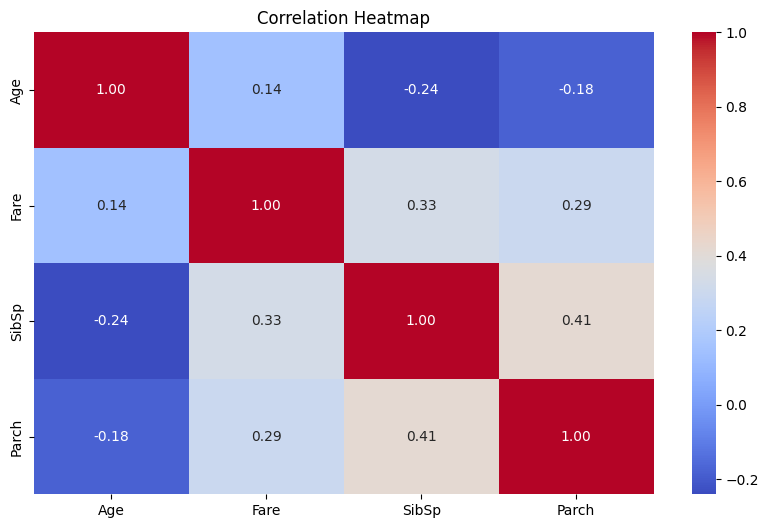

In [35]:
plt.figure(figsize=(10, 6))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()


Bar plots for average Fare and Age based on Pclass and Sex

<ipython-input-36-44ddf3173547>:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Pclass', y='Fare', data=df, ci=None, palette='Set2')
<ipython-input-36-44ddf3173547>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Fare', data=df, ci=None, palette='Set2')
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(

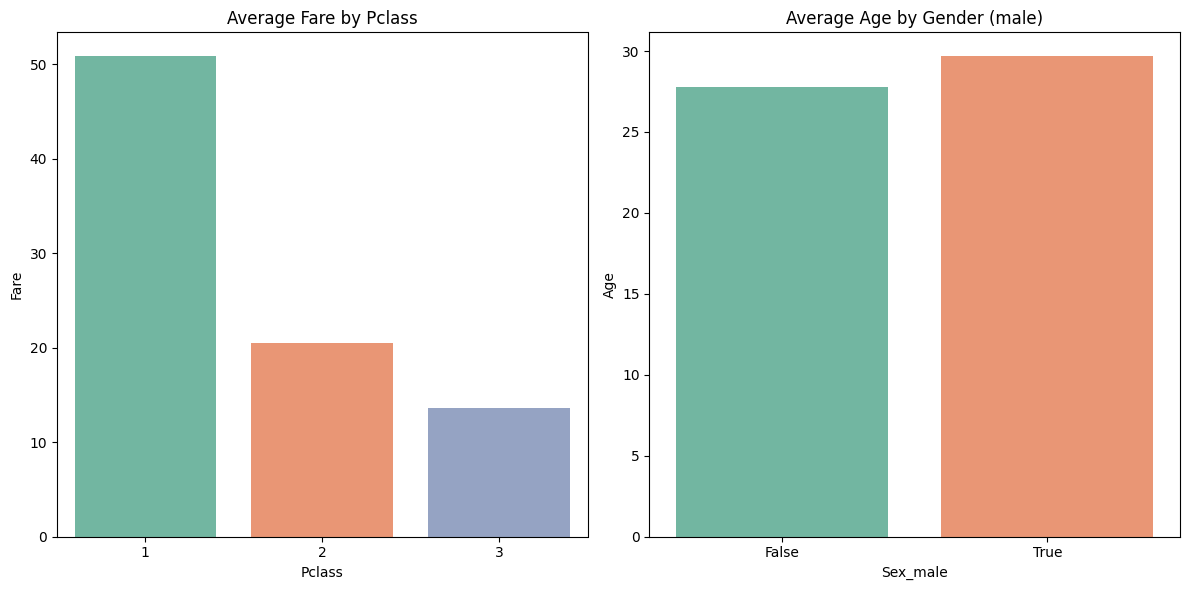

In [36]:
plt.figure(figsize=(12, 6))

# Average Fare by Pclass
plt.subplot(1, 2, 1)
sns.barplot(x='Pclass', y='Fare', data=df, ci=None, palette='Set2')
plt.title('Average Fare by Pclass')

# Average Age by Sex
plt.subplot(1, 2, 2)
sns.barplot(x='Sex_male', y='Age', data=df, ci=None, palette='Set2')
plt.title('Average Age by Gender (male)')

plt.tight_layout()
plt.show()


Analyzing skewness

Skewness of Numerical Features:
Age      0.130288
Fare     1.082179
SibSp    3.695352
Parch    2.749117
dtype: float64


<ipython-input-37-0cdb04a06579>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=skewness.index, y=skewness.values, palette='Set2')
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/usr/local/lib/python3.10/dist-packages/seaborn/_base.py:949: FutureWarning: When grouping with a lengt

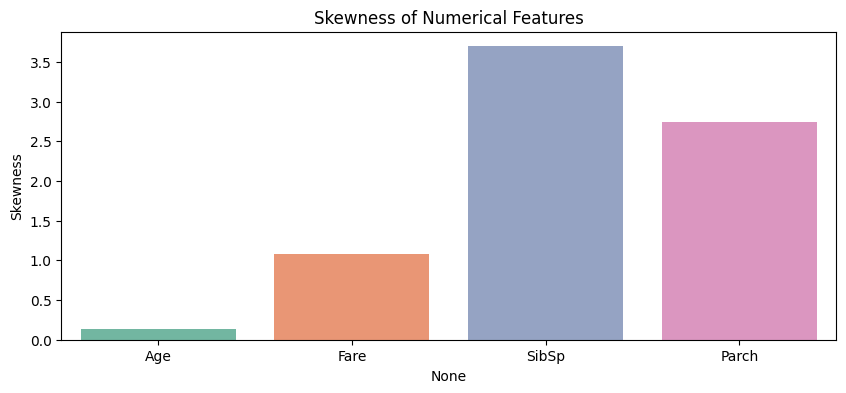

In [37]:
skewness = df[numerical_cols].skew() # Analyze skewness in numerical data

print('Skewness of Numerical Features:')
print(skewness)
plt.figure(figsize=(10, 4))# Plot the skewness
sns.barplot(x=skewness.index, y=skewness.values, palette='Set2')
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.title('Skewness of Numerical Features')
plt.ylabel('Skewness')
plt.show()

**Interpretation**
**AGE:** Age has a nearly normal distribution. Since the skewness is close to zero, no transformation is required for this feature.

**Fare (1.08):** Fare shows a moderate positive skew, indicating the presence of a long tail towards higher fares. A log transformation might help normalize this feature.

**SibSp (3.70) and Parch (2.75):** Both SibSp and Parch have high positive skewness, SO WE Can either apply a log transformation or square root transformation.

In [41]:
df['Fare_log'] = df['Fare'].apply(lambda x: np.log(x + 1))  # Adding 1 to avoid log(0)
new_skewness = df[['Age', 'Fare_log', 'SibSp', 'Parch']].skew() # Recalculatong skewness after transformation
print("Skewness after log transformation:")
print(new_skewness)
df['SibSp_sqrt'] = df['SibSp'].apply(lambda x: np.sqrt(x)) # square root transformation to SibSp and Parch

df['Parch_sqrt'] = df['Parch'].apply(lambda x: np.sqrt(x))
new_skewness_sqrt = df[['Age', 'Fare_log', 'SibSp_sqrt', 'Parch_sqrt']].skew() # Recalculate skewness after transformation

print("Skewness after square root transformation:")
print(new_skewness_sqrt)


Skewness after log transformation:
Age         0.130288
Fare_log   -0.237877
SibSp       3.695352
Parch       2.749117
dtype: float64
Skewness after square root transformation:
Age           0.130288
Fare_log     -0.237877
SibSp_sqrt    1.436526
Parch_sqrt    1.529799
dtype: float64


In [42]:
df['SibSp_cube'] = df['SibSp'].apply(lambda x: np.cbrt(x))# Apply cube root transformation to SibSp and Parch

df['Parch_cube'] = df['Parch'].apply(lambda x: np.cbrt(x))
new_skewness_cube = df[['Age', 'Fare_log', 'SibSp_cube', 'Parch_cube']].skew() # Recalculatong skewness after cube root transformation

print("Skewness after cube root transformation:")
print(new_skewness_cube)


Skewness after cube root transformation:
Age           0.130288
Fare_log     -0.237877
SibSp_cube    1.033059
Parch_cube    1.348334
dtype: float64


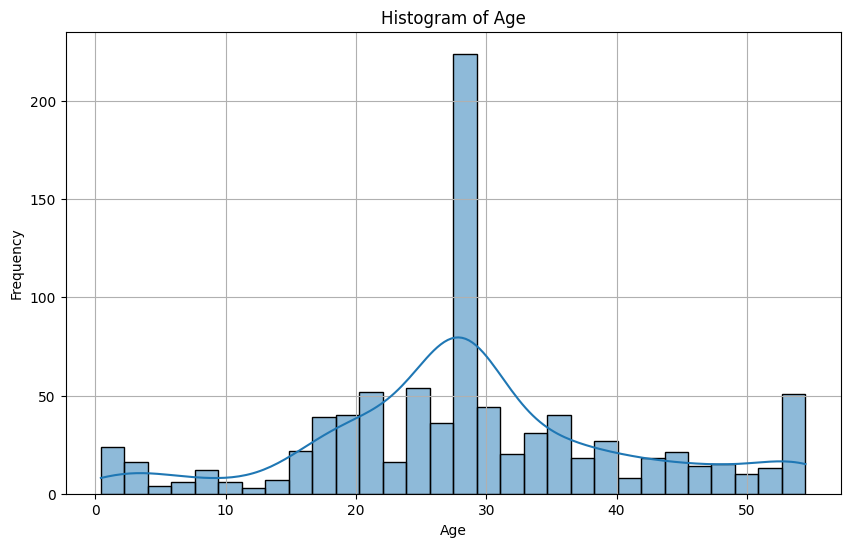

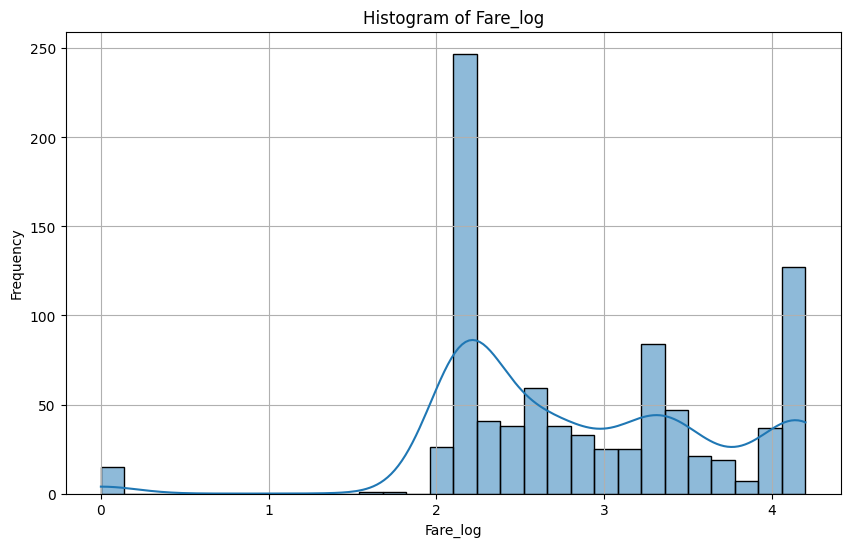

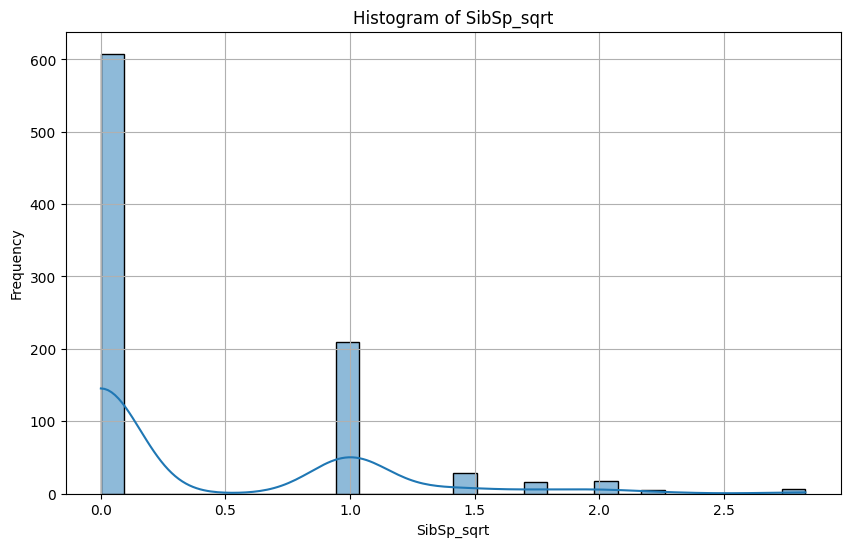

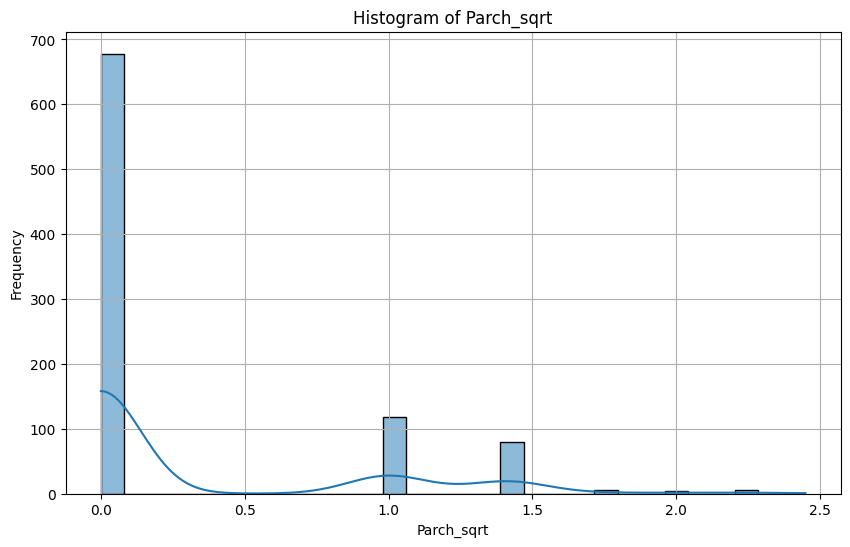

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# List of transformed numerical columns
transformed_cols = ['Age', 'Fare_log', 'SibSp_sqrt', 'Parch_sqrt']

# Plot histograms for each transformed feature
for col in transformed_cols:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[col].dropna(), bins=30, kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.show()


# **PART 7: Feature Scaling**

**Normalization:** scales the features to a fixed range, usually [0, 1], based on the minimum and maximum values. It's useful when: The features have different units or scales. Machine learning algorithms like k-NN, SVM, or neural networks that are sensitive to the scale of the input features.

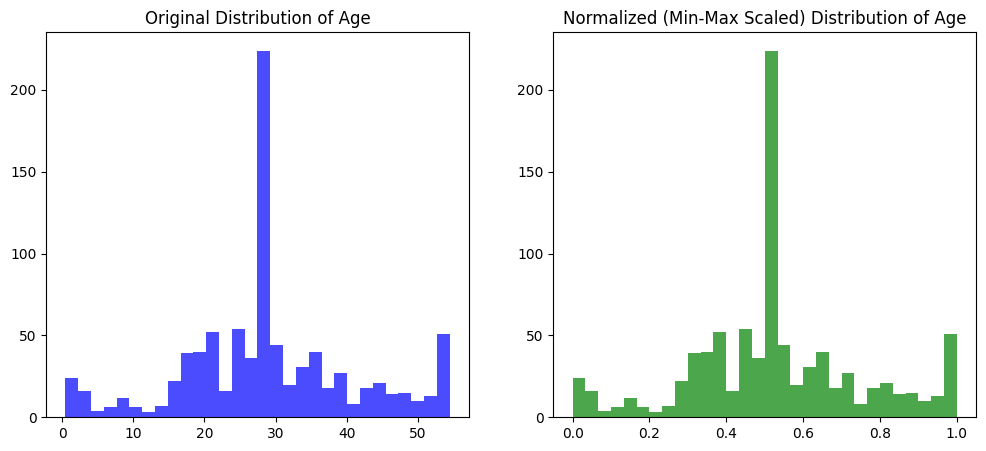

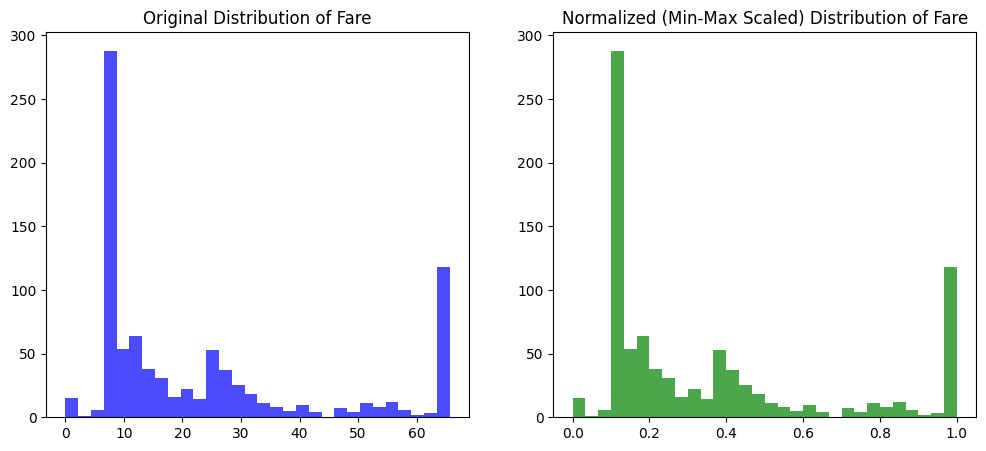

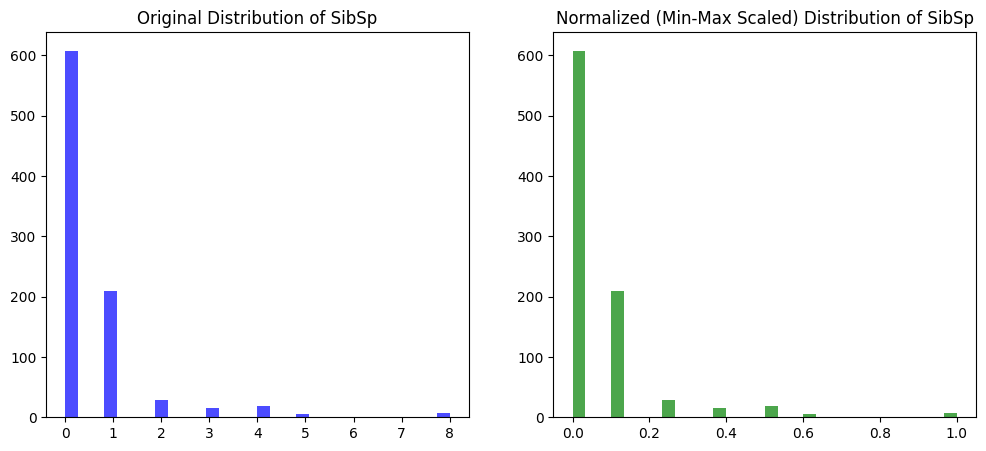

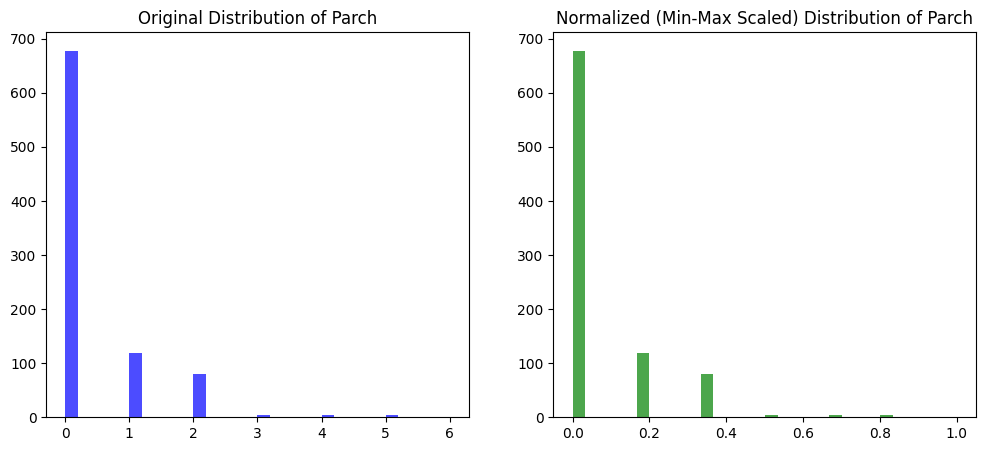

In [44]:
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Define the scaler
scaler = MinMaxScaler()

# Select numerical columns to scale
numerical_cols = ['Age', 'Fare', 'SibSp', 'Parch']

# Apply Min-Max Scaling
df_normalized = df.copy()
df_normalized[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# Plot histograms before and after scaling
for col in numerical_cols:
    plt.figure(figsize=(12, 5))

    # Original distribution
    plt.subplot(1, 2, 1)
    plt.hist(df[col], bins=30, color='blue', alpha=0.7)
    plt.title(f'Original Distribution of {col}')

    # Normalized distribution
    plt.subplot(1, 2, 2)
    plt.hist(df_normalized[col], bins=30, color='green', alpha=0.7)
    plt.title(f'Normalized (Min-Max Scaled) Distribution of {col}')

    plt.show()

**Standardization:** transforms the data to have a mean of 0 and a standard deviation of 1 (unit variance). This is important when:
The data has outliers.
The machine learning algorithms assume normally distributed data (e.g., linear regression, logistic regression).

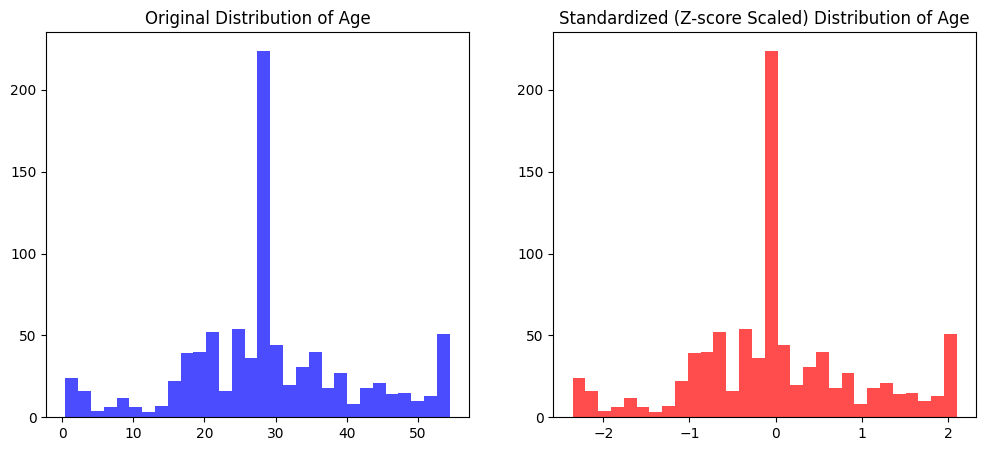

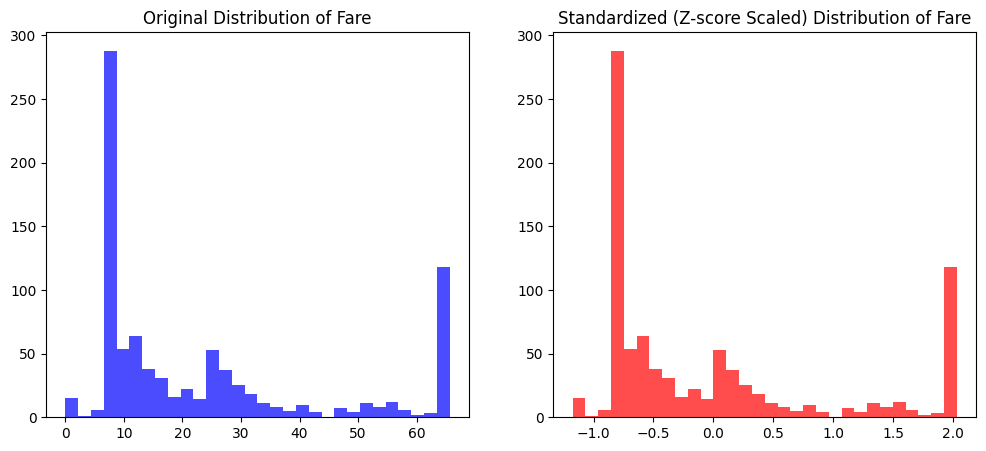

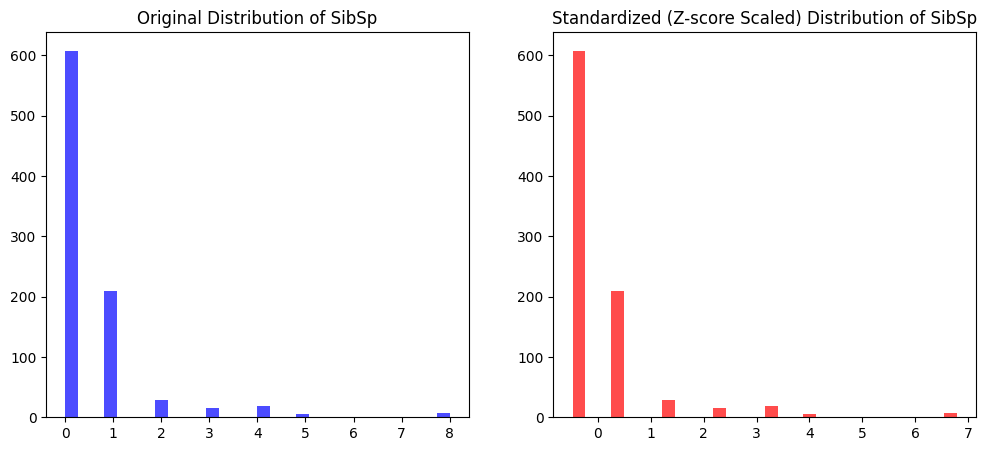

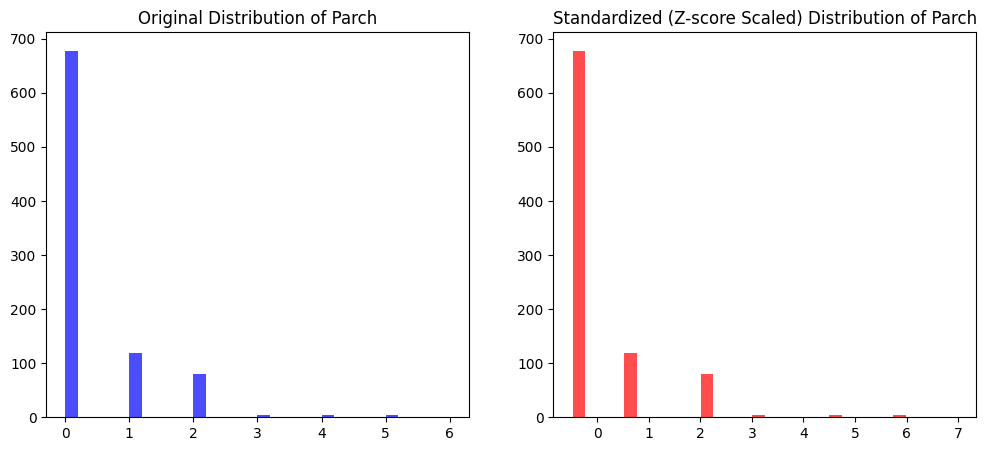

In [45]:
from sklearn.preprocessing import StandardScaler

# Define the scaler
scaler = StandardScaler()

# Apply Z-score Standardization
df_standardized = df.copy()
df_standardized[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# Plot histograms before and after scaling
for col in numerical_cols:
    plt.figure(figsize=(12, 5))

    # Original distribution
    plt.subplot(1, 2, 1)
    plt.hist(df[col], bins=30, color='blue', alpha=0.7)
    plt.title(f'Original Distribution of {col}')

    # Standardized distribution
    plt.subplot(1, 2, 2)
    plt.hist(df_standardized[col], bins=30, color='red', alpha=0.7)
    plt.title(f'Standardized (Z-score Scaled) Distribution of {col}')

    plt.show()

**Standardization** is preferred when:
Outliers exist in the data.
Normal distribution is assumed or required.
Features are on different scales.
Preservation of relationships among data points is crucial.

**Normalization** is suitable when:
Data needs to be bounded.
Outliers are not a concern.

# **Part 8: Final Dataset Overview**

**STEP 1:Handling Missing Values:**

Missing values in the Age column were imputed using the median value.
Missing values in the Fare column were filled with the mean.
The Cabin column was dropped due to a high percentage of missing values.
The Embarked column's missing values were filled with the mode.

**STEP 2: Detecting and Handling Outliers:**

Outliers in the Age and Fare columns were identified using Z-score and Interquartile Range (IQR) methods.
Outliers were capped (limited to upper/lower bounds) for Age and Fare to reduce their influence on the dataset.

**STEP 3: Dealing with Duplicates:**

Duplicate records were checked and removed, ensuring that the dataset only contains unique entries.

**STEP 4: Encoding Categorical Variables:**

Label Encoding was applied to the ordinal variable Pclass to convert it into numerical values.
One-Hot Encoding was applied to nominal variables Sex and Embarked, creating binary columns to represent these categories.

**STEP 5: Transforming Features:**

A log transformation was applied to the Fare column to reduce skewness.
A square root transformation was applied to the SibSp and Parch columns to further reduce their skewness.

**STEP 6: Feature Scaling:**

Normalization (Min-Max Scaling) was applied to scale features to a range of 0 to 1.
Standardization (Z-score Scaling) was also applied to standardize features to have a mean of 0 and standard deviation of 1.

In [46]:
df.head()


,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Age_zscore,Fare_zscore,Pclass_encoded,Sex_male,Embarked_Q,Embarked_S,Fare_log,SibSp_sqrt,Parch_sqrt,SibSp_cube,Parch_cube
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,-0.565736,-0.502445,2,True,False,True,2.110213,1.0,0.0,1.0,0.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,65.6344,0.663861,0.786845,0,False,False,False,4.199221,1.0,0.0,1.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,-0.258337,-0.488854,2,False,False,True,2.188856,0.0,0.0,0.0,0.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,0.433312,0.420730,0,False,False,True,3.990834,1.0,0.0,1.0,0.0
4,5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,0.433312,-0.486337,2,True,False,True,2.202765,0.0,0.0,0.0,0.0


# **Bonus Task: Dimensionality Reduction-Principal Component Analysis (PCA)**

In [47]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [49]:
numerical_features = ['Age', 'Fare_log', 'SibSp_sqrt', 'Parch_sqrt']
X = df[numerical_features] # Select only numerical features for PCA

In [50]:
scaler = StandardScaler() # Standardize the data
X_scaled = scaler.fit_transform(X)

In [51]:
pca = PCA() #APPLUING PCA TECHNIQUR
X_pca = pca.fit_transform(X_scaled)

PCA : Reduces Dimensionality,
Removes Redundancy,
Improves Visualization.

Feature Transformatio
Variance Explained: computes the amount of variance explained by each principal component. This ratio indicates how much information (variance) each principal component captures from the dataset.
It is crucial for determining how many principal components to keep. For example, if the first few components explain a significant portion of the variance (e.g., over 70-80%), you can choose to keep just those components for further analysis or modeling.
Dimension Reduction

In [52]:
explained_variance = pca.explained_variance_ratio_ # Explained variance by each principal component


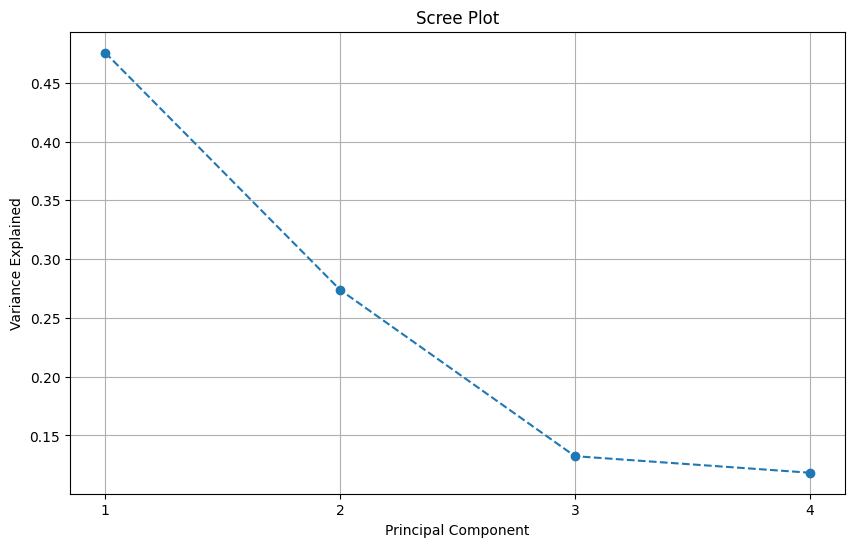

In [53]:
# Plotting the Scree Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid()
plt.show()

Text(0, 0.5, 'Principal Component 2')

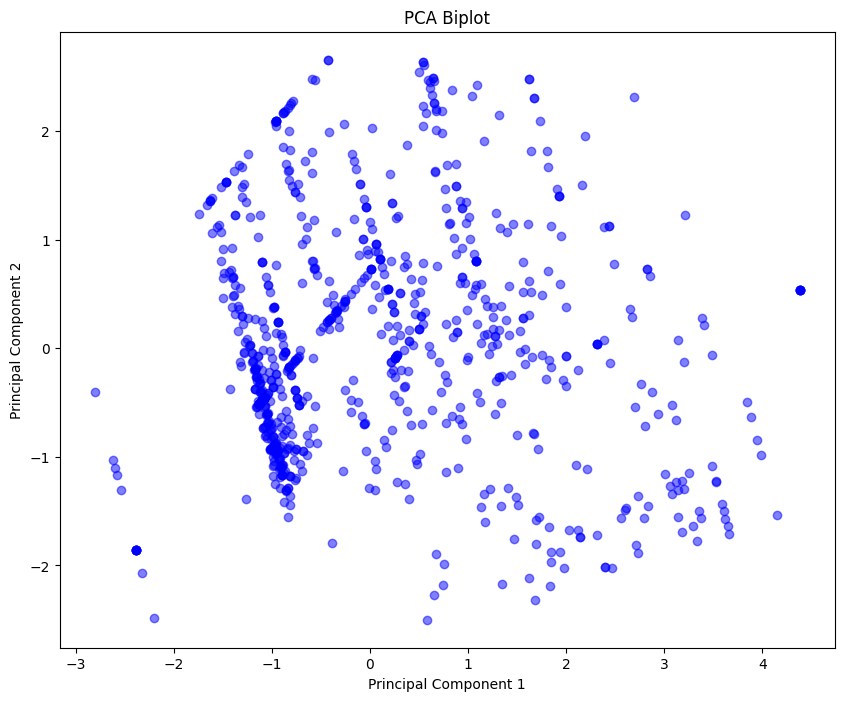

In [54]:
# Biplot
plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.5, color='blue')
plt.title('PCA Biplot')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

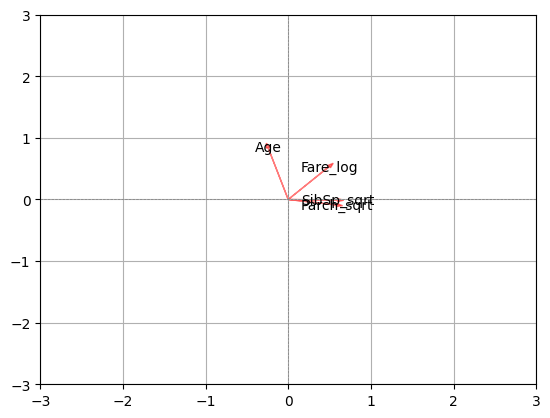

In [57]:
for i in range(len(numerical_features)): # Adding vectors for the features
    plt.arrow(0, 0, pca.components_[0, i], pca.components_[1, i],
              color='red', alpha=0.5, head_width=0.05)
    plt.text(pca.components_[0, i], pca.components_[1, i], numerical_features[i], color='black', ha='center', va='center')

plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.grid()
plt.axhline(0, color='grey', lw=0.5, ls='--')
plt.axvline(0, color='grey', lw=0.5, ls='--')
plt.show()

In [61]:
original_shape = df.shape  # e.g., (891, 13)
pca_shape = X_pca.shape  # e.g., (891, 5) after reducing to 5 components

print(f"Original shape: {original_shape}")
print(f"PCA shape: {X_pca}")


Original shape: (891, 20)
PCA shape: [[-3.77393538e-02 -9.48033182e-01 -9.36412821e-01 -8.57868757e-01]
 [ 8.75850274e-01  1.49457650e+00 -1.11515905e+00  2.18858065e-01]
 [-1.04692239e+00 -6.03509372e-01  2.14177874e-02 -1.88906938e-03]
 ...
 [ 2.00219728e+00 -7.12814181e-02  9.93000537e-01 -6.31271904e-01]
 [-3.10996869e-01  1.91390510e-01 -2.29688802e-01  9.90740217e-01]
 [-1.17904028e+00 -2.00286570e-01  1.16366045e-01 -2.38419100e-01]]


Visualize explained variance

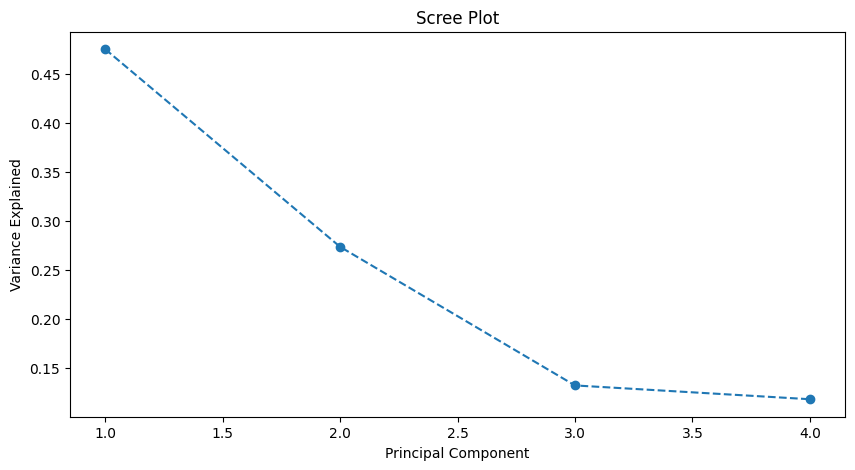

In [62]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.show()
